# 02 - QUANT's features with four classifiers (v1)

ExtraTrees (QUANT's own), XGBoost, CatBoost and TabPFN (the 500 most important features, ranked by ExtraTrees on the
training data) on the same QUANT features: the small and medium development datasets, resample 0. Settings and
commands: `experiments.md`, v1.

A first look, not a benchmark: 5 datasets per group and one split each, so no spread and no significance test
(lectures, week 9: the dataset is the unit of a test, and 5 datasets are too few for four classifiers). These 10
datasets are among the 34 used for development; the full benchmark is notebook 05.

## 1. Data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# the shared names, colours, plot style and loading of all notebooks: notebooks/common.py
from common import CLASSIFIERS, COLORS, GROUP_COLORS, LABELS, RESULTS_DIR, TEXT, load_runs, style

style()
GROUPS = ["small", "medium"]

# one table with every run of the two files, each run marked with its dataset group
frames = []
for group in GROUPS:
    d = load_runs(RESULTS_DIR / f"v1_smoke-{group}-r0_allcores-gpu.csv")
    d["group"] = group
    frames.append(d)
runs = pd.concat(frames, ignore_index=True)
ok = runs[runs["status"] == "ok"]

In [2]:
def grouped_bars(ax, values, groups, series, colors, fmt="{:.3f}", rotation=0, fontsize=8.5):
    """One group of bars per group, one bar per series (values[(group, series)]), each bar labelled with its value."""
    x = np.arange(len(groups))
    width = 0.8 / len(series)
    for k, s in enumerate(series):
        offset = (k - (len(series) - 1) / 2) * width              # the series side by side, centred on x
        heights = [values[(g, s)] for g in groups]              # values is keyed by (group, series)
        bars = ax.bar(x + offset, heights, width, color=colors[s], edgecolor="white",
                      linewidth=1.2, label=s)
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=fontsize, color=TEXT, rotation=rotation)
    return x

## 2. Accuracy and probability quality, small vs medium

The mean over the 5 datasets of each group (small: 28 to 100 training cases, medium: 467 to 2,403).

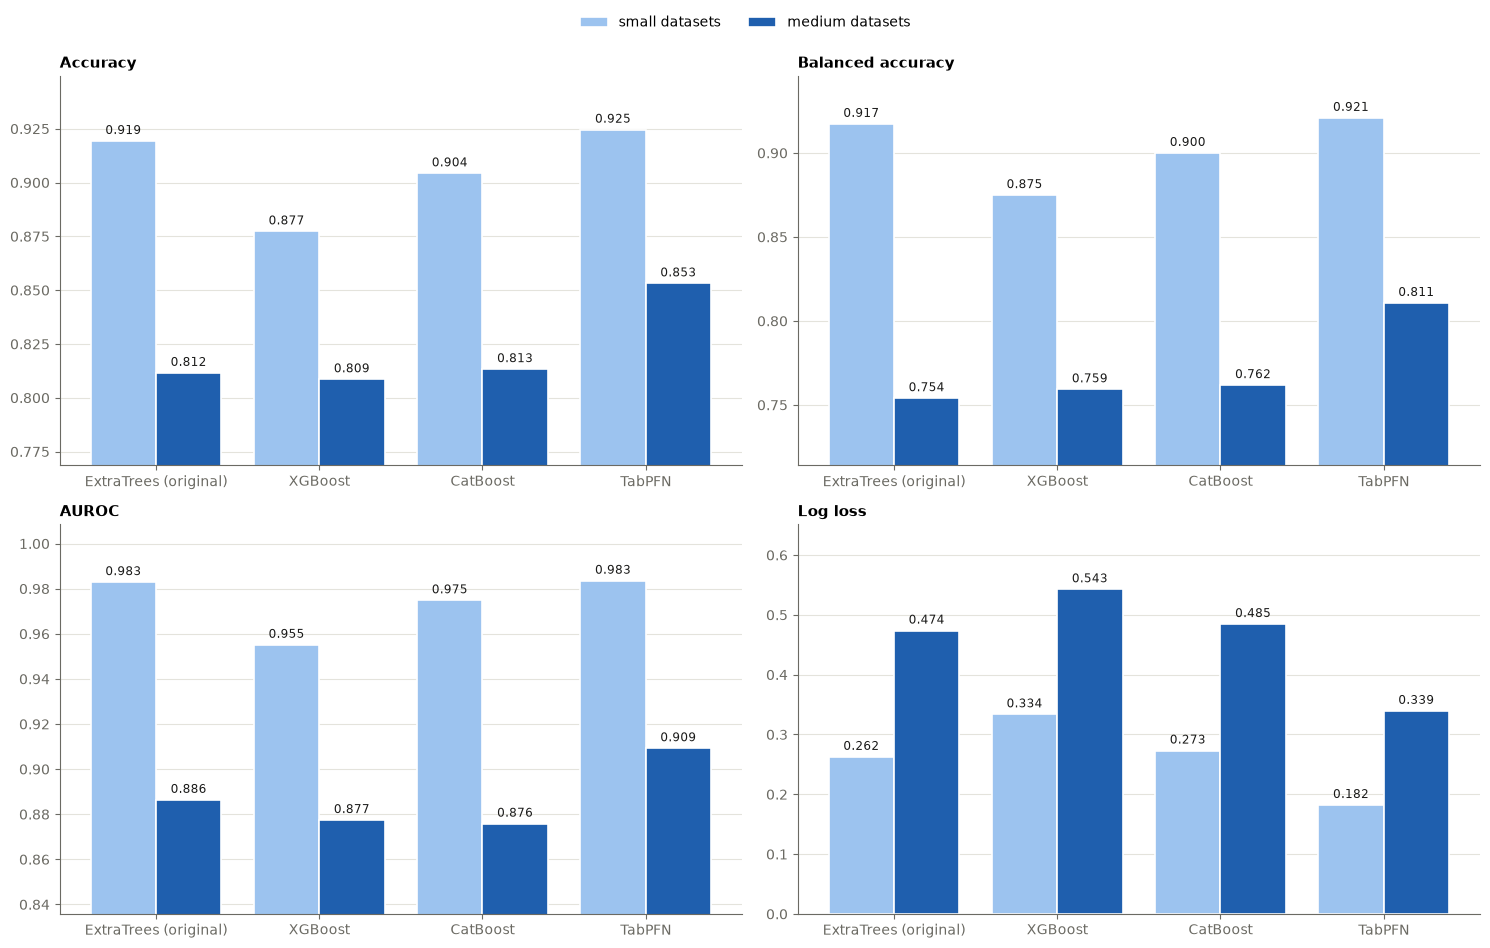

In [3]:
# the mean of each metric per classifier and dataset group, (used again in sections 3 and 4)
by_group = ok.groupby(["classifier", "group"])[
    ["accuracy", "balanced_accuracy", "auroc", "log_loss", "fit_predict", "total_time"]].mean()

panels = [("accuracy", "Accuracy"), ("balanced_accuracy", "Balanced accuracy"), ("auroc", "AUROC"), ("log_loss", "Log loss")]
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
for ax, (metric, title) in zip(axes.flat, panels):
    values = by_group[metric].to_dict()                           # (classifier, group) -> mean
    x = grouped_bars(ax, values, CLASSIFIERS, GROUPS, GROUP_COLORS)
    ax.set_xticks(x, [LABELS[c] for c in CLASSIFIERS])
    ax.set_title(title, loc="left")
    if metric == "log_loss":                                      # log loss from 0; the others zoomed in on the values
        ax.set_ylim(0, max(values.values()) * 1.2)
    else:
        ax.set_ylim(min(values.values()) - 0.04, min(1.0, max(values.values())) + 0.025)
handles, labels = axes[0, 0].get_legend_handles_labels()       # one legend for the four panels
fig.legend(handles, ["small datasets", "medium datasets"], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## 3. Time, small vs medium

Fit + predict per run.

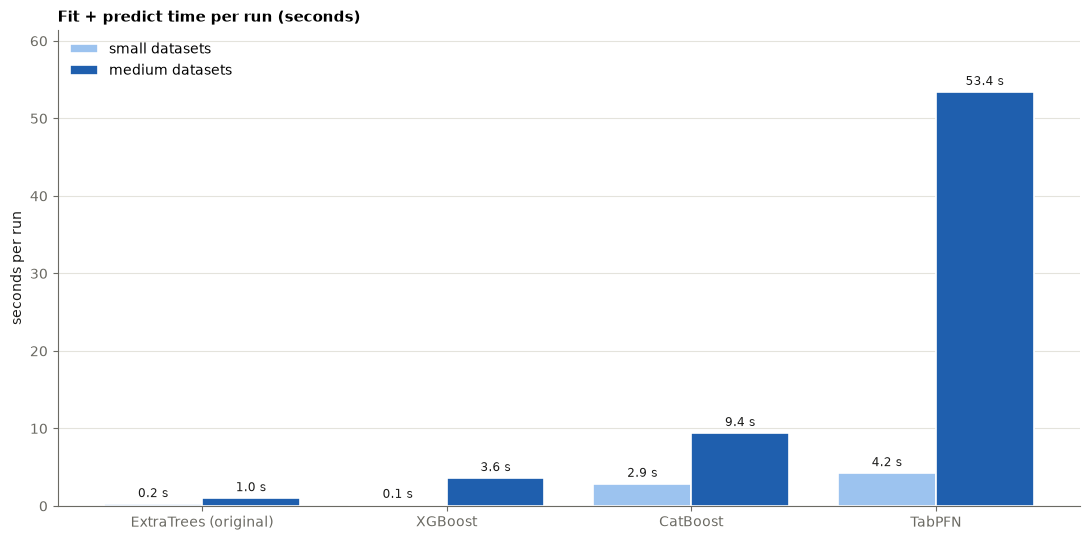

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.5))
values = by_group["fit_predict"].to_dict()
x = grouped_bars(ax, values, CLASSIFIERS, GROUPS, GROUP_COLORS, fmt="{:.1f} s")
ax.set_xticks(x, [LABELS[c] for c in CLASSIFIERS])
ax.set_ylim(0, max(values.values()) * 1.15)
ax.set_ylabel("seconds per run")
ax.set_title("Fit + predict time per run (seconds)", loc="left")
ax.legend(["small datasets", "medium datasets"], loc="upper left", frameon=False)
fig.tight_layout()
plt.show()

## 4. Accuracy vs time

One point per classifier and group (circles: small, squares: medium); up and to the left is better.

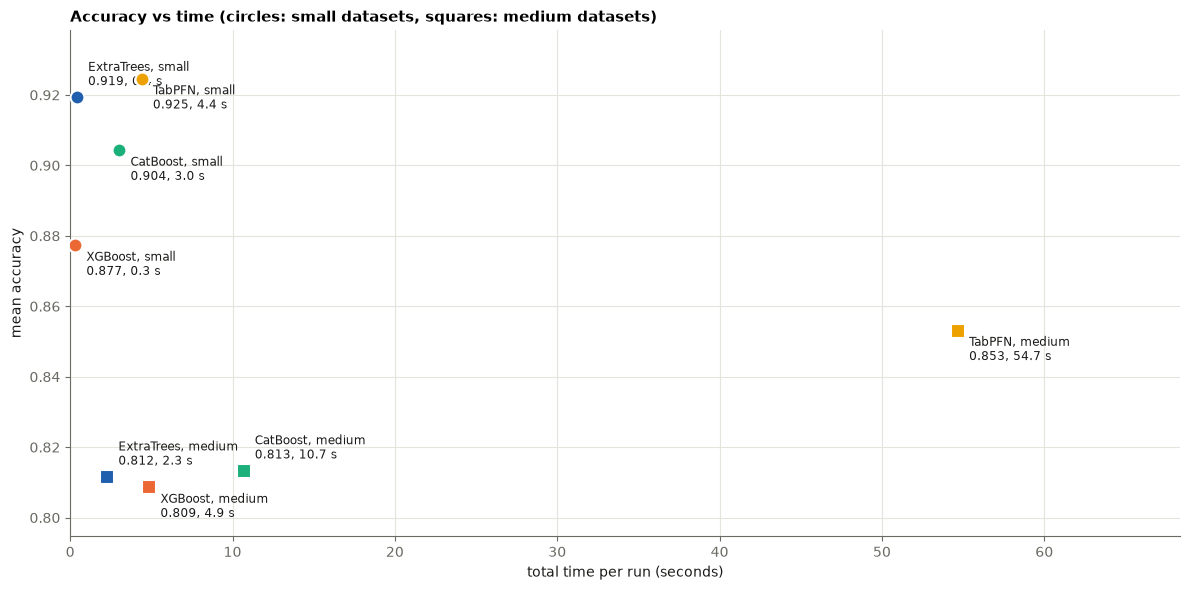

In [5]:
# where each label goes (offset in points, vertical alignment), so that the labels of nearby points do not overlap
LABEL_PLACE = {("extratrees", "small"): (8, 6, "bottom"), ("extratrees", "medium"): (8, 6, "bottom"),
               ("catboost", "medium"): (8, 6, "bottom")}
fig, ax = plt.subplots(figsize=(12, 6))
for clf in CLASSIFIERS:
    for group, marker in [("small", "o"), ("medium", "s")]:
        row = by_group.loc[(clf, group)]
        ax.scatter(row["total_time"], row["accuracy"], s=100, marker=marker, color=COLORS[clf], edgecolor="white",
                   linewidth=1.5, zorder=3)
        dx, dy, va = LABEL_PLACE.get((clf, group), (8, -3, "top"))
        name = LABELS[clf].split(" (")[0]                          # "ExtraTrees (original)" -> "ExtraTrees"
        ax.annotate(f"{name}, {group}\n{row['accuracy']:.3f}, {row['total_time']:.1f} s",
                    (row["total_time"], row["accuracy"]), xytext=(dx, dy), textcoords="offset points", fontsize=8.5,
                    color=TEXT, va=va)
ax.set_xlim(0, by_group["total_time"].max() * 1.25)
ax.set_xlabel("total time per run (seconds)")
ax.set_ylabel("mean accuracy")
ax.set_title("Accuracy vs time (circles: small datasets, squares: medium datasets)", loc="left")
ax.grid(True, axis="both")
ax.margins(y=0.12)
fig.tight_layout()
plt.show()

## 5. Observations

- **Most accurate: TabPFN on both groups** (small 0.925, medium 0.853), never worse than ExtraTrees on any dataset,
  and with the best probabilities. ExtraTrees is second on small (0.919); on medium ExtraTrees, CatBoost and XGBoost
  are tied (0.809-0.813).
- **Fastest: XGBoost on small (0.13 s), ExtraTrees on medium (1.0 s).** TabPFN is the slowest (4.2 s / 53.4 s).
- **From small to medium,** TabPFN's lead over ExtraTrees grows from +0.006 to +0.041, and the boosters catch up
  with ExtraTrees.
